# Image sources: simulating a sky image

`simulate_field` draws point sources from a catalogue. Many targets are not points: a
protoplanetary disk, a planet next to its star, a resolved galaxy, a radiative-transfer
model (e.g. POLARIS). wcc-sim can take such a model as a **sky image**: a 2-D FITS image
with a celestial WCS and physical pixel units (`BUNIT`). It then simulates what a WCC
detector records.

The pipeline has four steps. Each is a public piece that can be used on its own:

| Step | Object | What it does |
|---|---|---|
| 1. source | `SkyImageComponent.from_fits` | validated image (`ImageInput`): data ≥ 0, celestial WCS, explicit unit |
| 2. placement | `detector_frame` | detector WCS: centre, offset, position angle, (sub)array shape |
| 3. optics | `WCCObservation.rate_image()` | e⁻/s per detector pixel: flux → rate, flux-conserving resampling, PSF convolution |
| 4. exposure | `WCCObservation.expose()` | sky + dark, noise, saturation, ADU → `SimulatedField` |

`simulate_image(...)` runs all four steps in one call.

**Two image components.** `SkyImageComponent` (this notebook) takes physical units and renders on a sub-grid, which keeps compact structure in images finer than the detector pixel (a planet next to its star, ring edges). `ImageComponent` (tutorial 11, PHANGS-HST) takes an AB zero point and goes into `simulate_field` together with field stars, reprojected bilinearly onto the frame. `WCCObservation` keeps the PSF and
the rendered rates, so one set-up can be exposed many times.

This notebook builds a small synthetic scene (a star, an inclined ring and a planet),
runs it through each step, checks flux conservation, and writes the FITS file. Resampling
needs the optional `reproject` package: `pip install 'wcc-sim[image]'`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from astropy.wcs import WCS

import wcc_sim
from wcc_sim import SkyImageComponent, WCCObservation, detector_frame, simulate_image
from wcc_sim.fluxrate import band_fluxes, flux_to_rate
from wcc_sim.plotting import use_style

use_style()
print(f'wcc_sim {wcc_sim.__version__}')

wcc_sim 0.1.0


## 1. A synthetic sky image

The scene is a star of 0.1 Jy, a dust ring inclined by 60° (radius 0.25″, 5 mJy in
total) and a planet with a contrast of 10⁻³, 0.18″ from the star. The image has
4 mas pixels, about a quarter of the 16.9 mas detector pixel of the IMX455.

These are the header cards the simulator reads:
- a TAN WCS (`CRVAL` = the star, `CD` = pixel scale, North up and East left);
- `BUNIT = 'Jy/pixel'`: each pixel holds the band-mean flux density F_ν of the light
  in it;
- `BAND`: the band the fluxes refer to. Here it is the detector filter itself, so the
  conversion to count rates is exact. Radiative-transfer cubes (e.g. POLARIS) are
  first converted to such 2-D images.

total 0.10510 Jy in 200 x 200 px of 4.0 mas


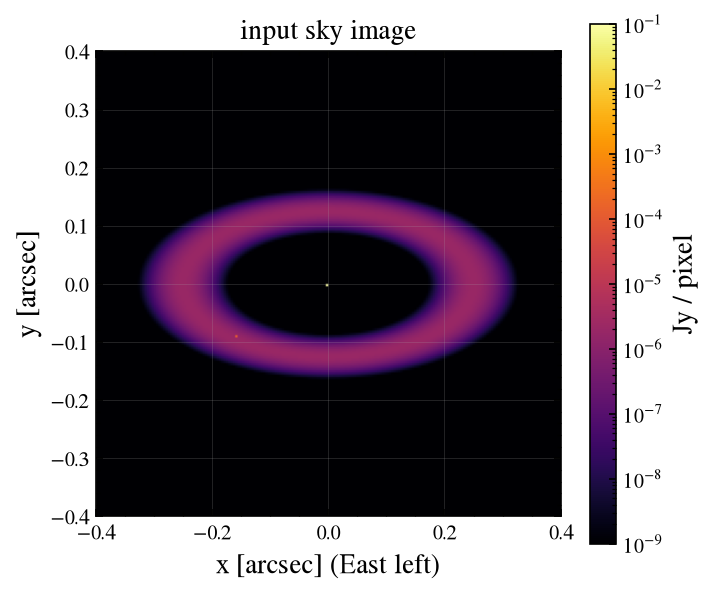

In [2]:
RA0, DEC0 = 212.0423106, -41.3979370      # star position [deg]
SCALE_MAS = 4.0
N = 200                                     # 0.8 arcsec field
SF = 'zwo:halpha2'

yy, xx = (np.mgrid[:N, :N] - (N - 1) / 2) * SCALE_MAS / 1000.0   # arcsec, +x = West
c = (N - 1) // 2
image = np.zeros((N, N))

# ring: radius 0.25", Gaussian width 0.02", inclined 60 deg (minor axis along y)
r = np.hypot(xx, yy / np.cos(np.radians(60.0)))
ring = np.exp(-0.5 * ((r - 0.25) / 0.02) ** 2)
image += 5e-3 * ring / ring.sum()
image[c, c] += 0.1                          # star, a point at the centre
pa_p, sep_p = np.radians(120.0), 0.18       # planet: PA 120 deg E of N, 0.18"
px = int(round(c - sep_p * np.sin(pa_p) / (SCALE_MAS / 1000)))   # East is -x
py = int(round(c + sep_p * np.cos(pa_p) / (SCALE_MAS / 1000)))
image[py, px] += 1e-4

def sky_header(ra, dec, scale_mas, crpix):
    # TAN WCS, East left / North up, BUNIT and BAND as the simulator reads them
    w = WCS(naxis=2)
    w.wcs.ctype = ['RA---TAN', 'DEC--TAN']
    w.wcs.crval = [ra, dec]
    w.wcs.crpix = [crpix, crpix]            # FITS is 1-based
    s = scale_mas / 3.6e6
    w.wcs.cd = [[-s, 0.0], [0.0, s]]
    h = w.to_header()
    h['BUNIT'] = 'Jy/pixel'
    h['BAND'] = SF
    return h

header = sky_header(RA0, DEC0, SCALE_MAS, c + 1)    # reference pixel = the star
fits.PrimaryHDU(image, header).writeto('scene.fits', overwrite=True)

ext = np.array([-0.5, N - 0.5, -0.5, N - 0.5]) - (N - 1) / 2
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(image, origin='lower', norm=LogNorm(1e-9, 1e-1), cmap='inferno',
               extent=ext * SCALE_MAS / 1000)
fig.colorbar(im, ax=ax, label='Jy / pixel')
ax.set(xlabel='x [arcsec] (East left)', ylabel='y [arcsec]', title='input sky image')
print(f'total {image.sum():.5f} Jy in {N} x {N} px of {SCALE_MAS} mas')

## 2. The source: `SkyImageComponent`

`SkyImageComponent.from_fits` accepts a path, an `HDUList`, an HDU or a `(data, header)`
pair. It rejects images that cannot be simulated faithfully:
- negative, NaN or all-zero data;
- a missing celestial WCS;
- a missing or conflicting unit. A unit is never assumed: without `BUNIT`, pass
  `flux_unit=`.

The validated `ImageInput` is available as `.image`.

In [3]:
comp = SkyImageComponent.from_fits('scene.fits')
img = comp.image
print('label       ', comp.label, '| kind', comp.kind)
print('unit        ', img.unit, '| band', img.band)
print('pixel scale ', f'{img.pixel_scale_mas:.3f} mas')
print('total       ', img.total)
print('centre      ', img.centre_radec)

try:
    bad = image.copy(); bad[0, 0] = -1e-9
    SkyImageComponent.from_fits((bad, header))
except ValueError as err:
    print('rejected:   ', err)

label        scene.fits | kind image
unit         Jy / pix | band zwo:halpha2
pixel scale  4.000 mas
total        0.10510000000000001 Jy / pix
centre       (212.04230985939247, -41.39793644444444)
rejected:    image contains 1 negative pixel(s) (minimum -1e-09); an intensity image is expected, e.g. not a Stokes Q/U plane


### Flux → count rate

`flux_to_rate(unit, sensorfilter)` gives the e⁻/s that one unit of pixel value produces
in a WCC filter. It is computed by wcc_etc for a flat spectrum through the telescope and
filter throughput.

Supported units:
- flux density per pixel (`Jy/pixel`);
- surface brightness (`Jy/arcsec2`, `MJy/sr`), scaled by the pixel area;
- F_λ;
- `electron/s`, passed through unchanged.

`band_fluxes` goes the other way, from a rate to the flux in the band.

In [4]:
per_jy = flux_to_rate('Jy/pixel', SF)
print(f'1 Jy/pixel in {SF}: {per_jy:,.0f} e-/s')
print(f'scene total      : {img.total.value * per_jy:,.1f} e-/s')
for k_, v in band_fluxes(img.total.value * per_jy, SF).items():
    print(f'  {k_:9s} {v:.5g}')
# surface brightness needs the pixel area; 1 Jy/arcsec2 on a 4 mas pixel:
print(f"1 Jy/arcsec2 -> {flux_to_rate('Jy/arcsec2', SF, (SCALE_MAS / 1000) ** 2):.1f} e-/s per pixel")

1 Jy/pixel in zwo:halpha2: 122,010 e-/s
scene total      : 12,823.2 e-/s


  f_nu_jy   0.1051
  f_lambda  7.3155e-14
  f_band    1.4632e-12
  pivot_nm  656.28
  width_nm  2.0001
1 Jy/arcsec2 -> 2.0 e-/s per pixel


## 3. The placement: `detector_frame`

`detector_frame(sensorfilter, centre, offset_arcsec, pa, shape)` returns a
`DetectorFrame`: the detector WCS together with the shape, pixel scale, filter and
pointing it was built from.
- The **offset** (dRA, dDec in arcsec) moves the pointing first, on the sky.
- **`pa`** then rotates the detector about the pointing: its +y axis points `pa`
  degrees East of North.
- **`shape`** selects a subarray centred on the pointing. The default is the full
  9568 × 6380 frame.

`simulate_field(..., offset_arcsec=...)` uses the same convention.

In [5]:
frame = detector_frame(SF, comp.centre_radec, offset_arcsec=(0.3, -0.2), pa=30.0,
                       shape=(201, 201))
print('pointing     ', frame.pointing)
print('centre/offset', frame.centre, frame.offset_arcsec)
print('plate scale  ', f'{frame.plate_scale_mas:.3f} mas/px', '| pa', frame.pa)
print('footprint    ', comp.footprint(frame.wcs, frame.shape), '(y0, y1, x0, x1)')

pointing      (212.0424209506189, -41.397991999946576)
centre/offset (212.04230985939247, -41.39793644444444) (0.3, -0.2)
plate scale   16.869 mas/px | pa 30.0
footprint     (69, 135, 89, 155) (y0, y1, x0, x1)


### Resampling onto the detector sub-grid

`rate_map` converts the image to e⁻/s and resamples it, flux-conservingly, onto a grid
**aligned with the detector**. That grid has k × k sub-pixels per detector pixel, where
k is the scale ratio rounded up to an odd number (at most 11).
- The resampling uses `reproject`'s exact overlap of spherical polygons, so a rotated or
  offset image keeps its total flux.
- The PSF is applied in the next step; the sub-grid keeps sub-pixel structure until
  then.

The result is a `Subgrid(data, y0, x0, k, total_in)`.

In [6]:
sub = comp.rate_map(frame.wcs, frame.shape, frame.plate_scale_mas, SF)
print(f'k = {sub.k}, cutout {sub.data.shape} sub-pixels at detector pixel (y0, x0) = ({sub.y0}, {sub.x0})')
print(f'input {sub.total_in:.3f} e-/s, on the sub-grid {sub.data.sum():.3f} e-/s')
assert np.isclose(sub.data.sum(), sub.total_in, rtol=1e-6)   # flux conserved

k = 5, cutout (330, 330) sub-pixels at detector pixel (y0, x0) = (69, 89)
input 12823.217 e-/s, on the sub-grid 12823.217 e-/s


## 4. The optics: `WCCObservation.rate_image()`

`WCCObservation(components, frame, focus=..., wings=..., scatter=...)` builds the PSF
the same way `simulate_field` does:
- an Airy core (or a defocused image), with jitter;
- the analytic wing beyond the stamp;
- the measured scattered-light halo.

It builds this for each sub-grid factor k it needs. `render_subgrid` then convolves every
sub-pixel phase with its shifted, pixel-binned stamp and sums them. This equals one
`add_star` per sub-pixel, but runs at detector resolution.

`rate_image()` is the noiseless e⁻/s image of the frame.

total: input 12823.2, no wings 12823.2, with wings+halo 12610.0 e-/s


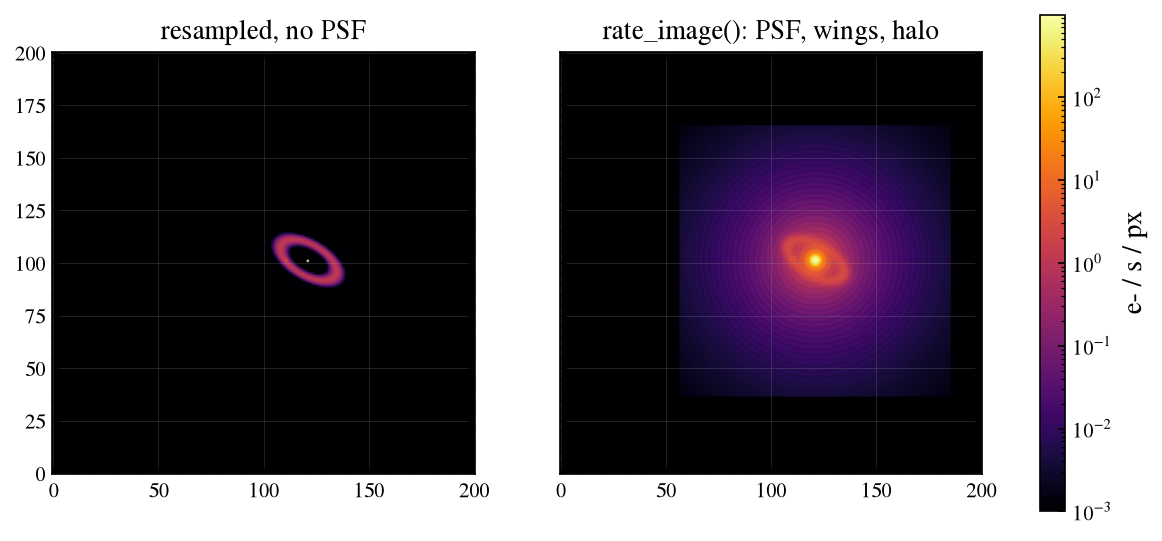

In [7]:
obs = WCCObservation(comp, frame, focus=0)
rate = obs.rate_image()
plain = WCCObservation(comp, frame, focus=0, wings=False).rate_image()

unconv = np.zeros(frame.shape)          # the resampled image binned to detector pixels
k = sub.k
binned = sub.data.reshape(sub.data.shape[0] // k, k, sub.data.shape[1] // k, k).sum((1, 3))
unconv[sub.y0:sub.y0 + binned.shape[0], sub.x0:sub.x0 + binned.shape[1]] = binned

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharex=True, sharey=True)
for ax, a, title in zip(axes, (unconv, rate), ('resampled, no PSF', 'rate_image(): PSF, wings, halo')):
    im = ax.imshow(np.maximum(a, 1e-6), origin='lower', norm=LogNorm(1e-3, a.max()), cmap='inferno')
    ax.set_title(title)
fig.colorbar(im, ax=axes, label='e- / s / px')
print(f'total: input {sub.total_in:.1f}, no wings {plain.sum():.1f}, with wings+halo {rate.sum():.1f} e-/s')

- **Without wings** the rendered total equals the input to float32 precision.
- **With wings and halo** a few per cent are missing: that light falls outside the PSF
  stamp, into the far wing and halo. Stars drawn by `simulate_field` carry it out to a
  noise floor; image cutouts are truncated at the stamp edge, as `render_extended`
  does.

The planet, about 10.7 detector pixels from the star, sits on the star's halo. A radial
profile shows it as a bump above the azimuthal mean.

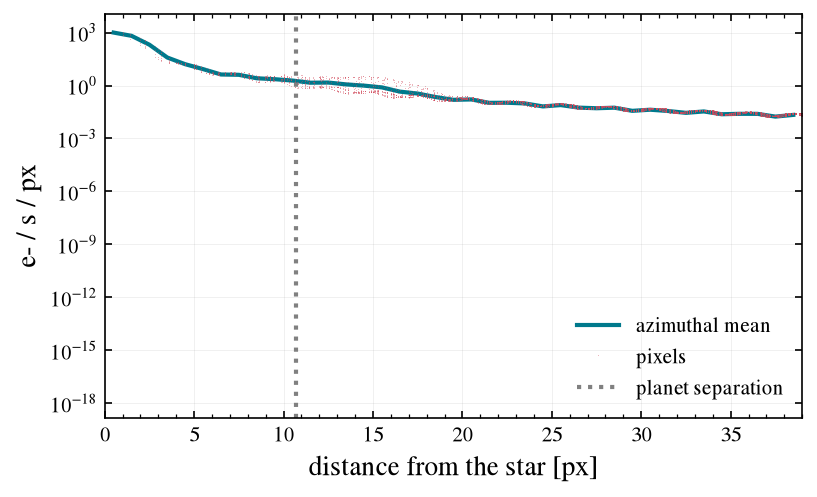

In [8]:
assert np.isclose(plain.sum(), sub.total_in, rtol=1e-5)

iy, ix = np.unravel_index(np.argmax(rate), rate.shape)
yy_d, xx_d = np.mgrid[:rate.shape[0], :rate.shape[1]]
rr = np.hypot(xx_d - ix, yy_d - iy)
edges = np.arange(0, 40, 1.0)
prof = [rate[(rr >= a) & (rr < b)].mean() for a, b in zip(edges[:-1], edges[1:])]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(edges[:-1] + 0.5, prof, label='azimuthal mean')
ax.semilogy(rr.ravel(), rate.ravel(), ',', alpha=0.4, label='pixels')
ax.axvline(sep_p * 1000 / frame.plate_scale_mas, color='0.5', ls=':', label='planet separation')
ax.set(xlabel='distance from the star [px]', ylabel='e- / s / px', xlim=(0, 39))
ax.legend();

## 5. The exposure: `expose()` → `SimulatedField`

`expose(exptime, n_reads, seed, add_noise)` multiplies the rate image by the exposure
time and applies the same detector model as `simulate_field` (sky + dark, per-frame
saturation, Poisson and read noise, gain and ADC).

It returns the usual `SimulatedField`:
- the images: `image_adu`, `image_e`, `image_clean`, `saturation_mask`;
- `wcs`, `params` and `models`;
- an **empty** star catalogue;
- the new `components` table.

The PSF and rendering are not repeated, so further exposures of the same observation are
cheap.

    10 s: peak    10308 e-, 0 saturated px, seed 1
   120 s: peak    16469 e-, 20 saturated px, seed 2


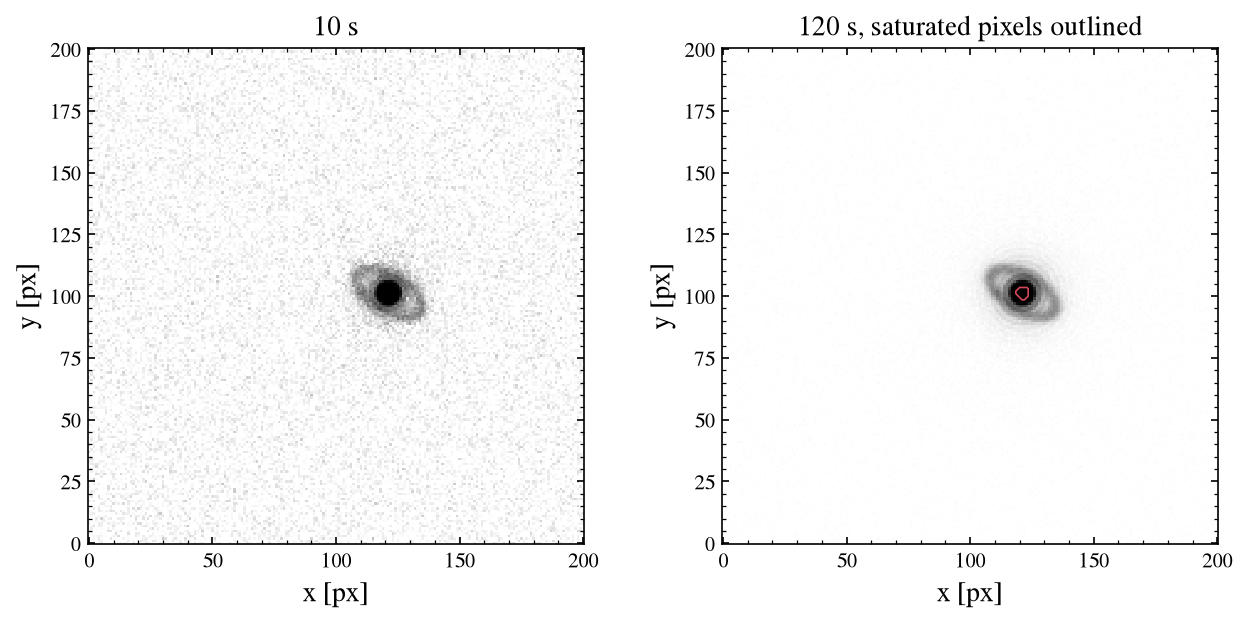

In [9]:
short = obs.expose(exptime=10.0, seed=1)
long = obs.expose(exptime=120.0, seed=2)
for f in (short, long):
    print(f"{f.params['exptime']:6.0f} s: peak {f.image_e.max():8.0f} e-, "
          f"{int(f.saturation_mask.sum())} saturated px, seed {f.params['seed']}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
short.plot(ax=axes[0]); axes[0].set_title('10 s')
long.plot(ax=axes[1], satmask=True); axes[1].set_title('120 s, saturated pixels outlined');

The `components` table has one row per component:
- what was simulated: the source, `BUNIT` as written, band, centre, size;
- the rate factor;
- where it landed: k and the cutout origin;
- the total and on-frame rates;
- the band fluxes.

In [10]:
short.components

label,kind,source,bunit,unit,band,centre_ra,centre_dec,nx,ny,pixel_scale_mas,rate_per_unit,subgrid_k,y0,x0,on_frame_e_s,total_e_s,f_nu_jy,f_lambda,f_band
,,,,,,,,,,mas,,,,,,,Jy,erg / (Angstrom s cm2),erg / (s cm2)
str10,str5,str10,str8,str8,str11,float64,float64,int64,int64,float64,float64,int64,int64,int64,float64,float64,float64,float64,float64
scene.fits,image,scene.fits,Jy/pixel,Jy / pix,zwo:halpha2,212.04230985939247,-41.39793644444444,200,200,3.999999999999961,122009.67437599848,5,69,89,12609.959785966996,12823.216776917443,0.10510000000000003,7.315532358502907e-14,1.4632159972781832e-12


## 6. One call: `simulate_image`

`simulate_image(image, ...)` chains steps 1–4:
- **Pointing:** by default the detector is centred on the image centre (from its WCS);
  `ra=`/`dec=` set the centre explicitly.
- **Other arguments:** the same names as in `simulate_field` (`sensorfilter`, `focus`,
  `exptime`, `n_reads`, `wings`, `scatter`, `seed`, `output`, …), plus
  `offset_arcsec`, `pa`, `subgrid` and `shape`.
- **Fluxes are taken from the image.** Scale the model beforehand if needed, e.g. normalise
  it in the detector band.

`output=` writes the usual multi-extension FITS file, with an extra **COMP** table.

In [11]:
field = simulate_image('scene.fits', sensorfilter=SF, focus=0, offset_arcsec=(0.3, -0.2),
                       pa=30.0, shape=(201, 201), exptime=10.0, seed=1,
                       output='scene_sim.fits')
with fits.open('scene_sim.fits') as h:
    h.info()
    hdr = h['SCI'].header
    for card in ('SENSORF', 'PA', 'EXPTIME', 'PNTSRC', 'CEN_RA', 'CEN_DEC', 'OFFSRA', 'OFFSDEC',
                 'IMGTOT', 'IMGRATE', 'IMGSUBK', 'IMGBUNIT', 'FLUXORIG', 'FLUXJY', 'FLUXFLAM',
                 'FLUXBAND', 'BANDPIV', 'BANDWID'):
        print(f'{card:8s} = {hdr[card]!r:28} / {hdr.comments[card]}')
np.testing.assert_array_equal(field.image_adu, short.image_adu)   # same as the step-by-step run

Filename: scene_sim.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SCI           1 PrimaryHDU      78   (201, 201)   float32   
  1  SATMASK       1 ImageHDU         8   (201, 201)   uint8   
  2  CAT           1 BinTableHDU     33   0R x 12C   [K, D, D, D, D, D, 8A, L, D, D, L, L]   
  3  CLEAN         1 ImageHDU         9   (201, 201)   float32   
  4  COMP          1 BinTableHDU     53   1R x 20C   [10A, 5A, 10A, 8A, 8A, 11A, D, D, K, K, D, D, K, K, K, D, D, D, D, D]   


SENSORF  = 'zwo:halpha2'                / wcc_etc sensorfilter (kind:band)
PA       = 30.0                         / [deg] position angle, E of N
EXPTIME  = 10.0                         / [s] total exposure time
PNTSRC   = 'image'                      / CEN_RA/CEN_DEC from: image (WCS) or user
CEN_RA   = 212.04230985939247           / [deg] centre the pointing offset is applied to
CEN_DEC  = -41.39793644444444           / [deg] centre the pointing offset is applied to
OFFSRA   = 0.3                          / [arcsec] pointing offset in RA from CEN_RA
OFFSDEC  = -0.2                         / [arcsec] pointing offset in Dec from CEN_DEC
IMGTOT   = 12823.216776917443           / [e-/s] total rate of the input image(s)
IMGRATE  = 12609.959785966996           / [e-/s] rate on the frame after PSF + clipping
IMGSUBK  = '5'                          / sub-pixels per detector pixel used (COMP)
IMGBUNIT = 'Jy/pixel'                   / BUNIT of the input image(s), as written
FLUXORIG = 'input i

`FLUXJY` recovers the 0.105 Jy of the input. The `FLUX*` cards give the total flux in
the detector band in three ways:
- the band-mean F_ν (`FLUXJY`);
- F_λ at the pivot (`FLUXFLAM`);
- the band-integrated flux (`FLUXBAND`) = F_λ × the band's top-hat width.

## 7. Several components

`WCCObservation` takes a list of components. Each one is resampled with its own k and
rendered separately, and the results are added. A component that misses the detector
is skipped with a warning; its COMP row has `subgrid_k = -1`.

Here the planet is moved into its own, coarser image (16 mas pixels, about the detector
pixel, so k = 3), and a second copy of the scene lies 30″ away, off the subarray.

In [12]:
import warnings

planet_only = np.zeros((25, 25)); planet_only[12, 12] = 1e-4
ra_p, dec_p = WCS(header).pixel_to_world_values(px, py)    # planet position on the sky
hp = sky_header(float(ra_p), float(dec_p), 16.0, 13)
far = sky_header(RA0, DEC0 + 30 / 3600, SCALE_MAS, c + 1)

no_planet = image.copy(); no_planet[py, px] -= 1e-4
parts = [SkyImageComponent.from_fits((no_planet, header), label='star + ring'),
         SkyImageComponent.from_fits((planet_only, hp), label='planet'),
         SkyImageComponent.from_fits((image, far), label='far copy')]
multi = WCCObservation(parts, frame, focus=0)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    combined = multi.expose(exptime=10.0, seed=1)
print([str(w_.message)[:60] for w_ in caught if 'overlap' in str(w_.message)])
combined.components['label', 'subgrid_k', 'total_e_s', 'on_frame_e_s', 'f_nu_jy']

['image does not overlap the detector; nothing to resample']


label,subgrid_k,total_e_s,on_frame_e_s,f_nu_jy
,,,,Jy
str11,int64,float64,float64,float64
star + ring,5,12811.015809479843,12597.961731847654,0.10500000000000001
planet,3,12.200967437599848,11.998023208620367,0.0001
far copy,-1,12823.216776917441,0.0,0.1051


## 8. Practical notes

- **Fluxes are a flat-spectrum transfer** when the image's `BAND` differs from the
  detector filter. A warning says so. Normalise the model in the detector band (e.g.
  `zwo:halpha2`) for exact rates.
- **Memory:** a full frame is 9568 × 6380 pixels (244 MB per float32 image). Use
  `shape=` for subarrays around the target.
- **Truncation:** image cutouts are truncated at the PSF stamp edge (a few per cent of
  the light, section 4). Point sources in `simulate_field` are drawn out to the noise
  floor.
- **Diagnostics:** `field.plot()` and `plot_satmask()` work. The star-based ones
  (`plot_cutout`, `plot_psf_profile`, `psf_report`) need a catalogue star.
- **Stars and images in one frame** (an image plus Gaia field stars) are planned: the
  image will become an extended component of `simulate_field`.

In [13]:
import os
for f in ('scene.fits', 'scene_sim.fits'):
    os.remove(f)